# EDA — Validasi Sampling & Insight Dialog (MultiWOZ)

**Tujuan notebook ini:** menjelaskan *hasil sampling* dan menggali *insight* dari data dialog
customer-service / task-oriented (MultiWOZ).

Sampling yang dipakai = **cluster-based (stratified) sampling**: populasi dikelompokkan ke
~100 cluster, lalu ~20 dialog diambil dari tiap cluster. Karena itu, EDA difokuskan ke dua
pertanyaan utama:

1. **Apakah sampel representatif terhadap populasi penuh?** (distribusi panjang, domain, leksikal)
2. **Insight apa yang muncul** dari struktur dialog dan dari cluster?

> **Cara pakai:** sesuaikan nama file di bagian *Config* bila perlu, lalu jalankan dari atas ke bawah.
> Tiap bagian mencetak ringkasan **INSIGHT** dalam bahasa natural di bawah grafiknya.

## 0. Setup & Load Data

In [1]:
import json, re, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Config: sesuaikan nama file bila berbeda ---
F_POP        = "multiwoz/dialogue_train.json"               # populasi penuh
F_TRAIN      = "multiwoz/multiwoz_sampled_2500_train.json"  # sampel train
F_TEST       = "multiwoz/multiwoz_sampled_2500_test.json"   # sampel test
F_AUDIT      = "multiwoz/multiwoz_sampled_2500_audit.json"  # metadata sampling (ids + cluster)
TEXT_COL     = 0   # kolom teks dialog (file ini menyimpan dialog di kolom "0")

In [2]:
def load_dialogues(path):
    """Load file dialog -> Series teks. Robust terhadap kolom 0 / 'text' / dll."""
    df = pd.read_json(path)
    col = TEXT_COL if TEXT_COL in df.columns else df.columns[0]
    s = df[col].astype(str)
    return s

pop   = load_dialogues(F_POP)
train = load_dialogues(F_TRAIN)
test  = load_dialogues(F_TEST)

with open(F_AUDIT) as f:
    audit = json.load(f)
selected_ids = audit.get("selected_ids", [])
cluster_map  = audit.get("cluster_assignments", {})   # {id: cluster}

print(f"Populasi : {len(pop):>6,} dialog")
print(f"Train    : {len(train):>6,} dialog")
print(f"Test     : {len(test):>6,} dialog")
print(f"selected_ids        : {len(selected_ids):,}")
print(f"cluster_assignments : {len(cluster_map):,}")
pop.head()

Populasi :  8,437 dialog
Train    :  2,000 dialog
Test     :    499 dialog
selected_ids        : 2,000
cluster_assignments : 2,000


0    user: I'd really like to take my client out to...
1    user: Looking for a place to eat in the city c...
2    user: Is there any expensive seafood restauran...
3    user: I'm looking for hotels in the center.\na...
4    user: I need a taxi to take me to the hotel fr...
Name: 0, dtype: object

## 1. Parsing Struktur Dialog

Tiap dialog satu baris teks, dengan turn dipisah `\n` dan diawali peran `user:` / `system:` (atau `agent:`).
Fungsi di bawah memecah dialog menjadi turn, menghitung jumlah turn, kata, dan mendeteksi domain
(hotel, restaurant, taxi, attraction, train) lewat keyword.

In [3]:
ROLE_RE = re.compile(r'^(user|system|agent|assistant|bot)\s*:\s*', re.I)

DOMAIN_KEYWORDS = {
    "hotel":      ["hotel", "guesthouse", "guest house", "stay", "room", "lodge", "star"],
    "restaurant": ["restaurant", "eat", "food", "dine", "dinner", "lunch", "cuisine", "table"],
    "taxi":       ["taxi", "cab", "pick me up", "pickup"],
    "train":      ["train", "departure", "arrive by", "leave after", "trainid"],
    "attraction": ["attraction", "museum", "park", "college", "gallery", "nightclub", "theatre"],
}

def split_turns(text):
    return [t for t in str(text).split("\n") if t.strip()]

def turn_role(turn):
    m = ROLE_RE.match(turn.strip())
    if not m: return "unknown"
    r = m.group(1).lower()
    return "user" if r in ("user",) else "system"

def clean_turn(turn):
    return ROLE_RE.sub("", turn.strip())

def n_words(text):
    return len(re.findall(r"\w+", str(text)))

def detect_domains(text):
    t = str(text).lower()
    return [d for d, kws in DOMAIN_KEYWORDS.items() if any(k in t for k in kws)]

def dialogue_features(text):
    turns = split_turns(text)
    roles = [turn_role(t) for t in turns]
    bodies = [clean_turn(t) for t in turns]
    doms = detect_domains(text)
    return {
        "n_turns":      len(turns),
        "n_user":       roles.count("user"),
        "n_system":     roles.count("system"),
        "n_words":      n_words(text),
        "n_chars":      len(str(text)),
        "words_per_turn": np.mean([n_words(b) for b in bodies]) if bodies else 0,
        "n_domains":    len(doms),
        "domains":      doms,
        "is_multidomain": len(doms) > 1,
    }

def build_frame(series, name):
    feats = series.apply(dialogue_features).apply(pd.Series)
    feats["split"] = name
    feats["text"]  = series.values
    return feats

f_pop   = build_frame(pop,   "population")
f_train = build_frame(train, "train")
f_test  = build_frame(test,  "test")
f_sample = pd.concat([f_train, f_test], ignore_index=True)
f_sample["split_grp"] = "sample"
f_pop["split_grp"] = "population"

print("Contoh fitur per dialog:")
f_train[["n_turns","n_user","n_system","n_words","words_per_turn","n_domains","is_multidomain"]].head()

Contoh fitur per dialog:


,n_turns,n_user,n_system,n_words,words_per_turn,n_domains,is_multidomain
0,10,5,5,132,12.200,2,True
1,6,3,3,60,9.000,3,True
2,8,4,4,95,10.875,2,True
3,12,6,6,135,10.250,3,True
4,10,5,5,176,16.600,2,True


## 2. Representativitas — Distribusi Panjang Dialog

Pertanyaan: **apakah sampel meniru populasi?** Kalau distribusi panjang (jumlah turn & kata)
sampel berbeda jauh dari populasi, sampel bias terhadap dialog pendek/panjang.

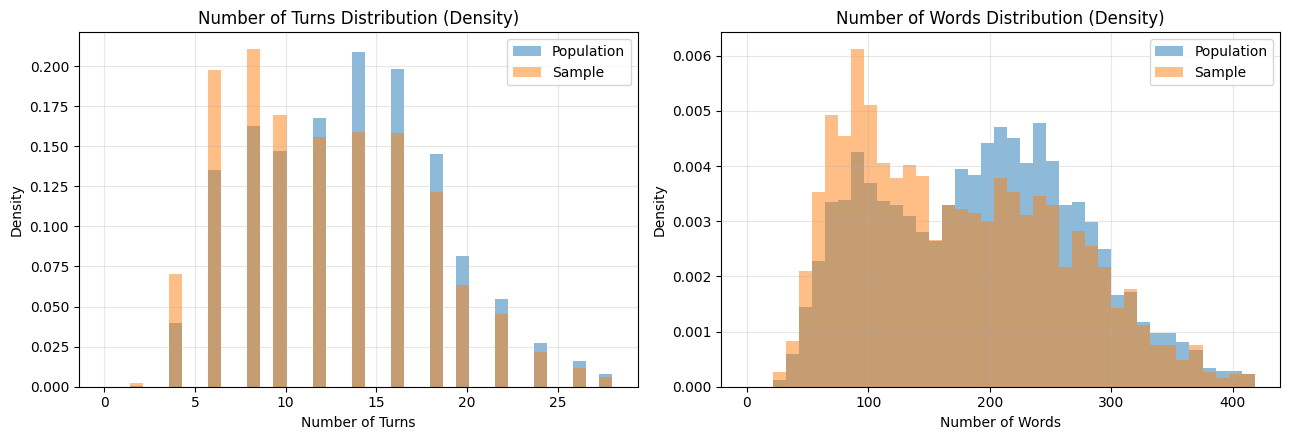

In [16]:
def describe_len(df, label):
    d = df[["n_turns", "n_words", "words_per_turn"]].describe(
        percentiles=[.5, .9, .95, .99]
    ).T
    d.insert(0, "dataset", label)
    return d

summary = pd.concat([
    describe_len(f_pop, "population"),
    describe_len(f_train, "train"),
    describe_len(f_test, "test"),
])

# display(summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, col, title in zip(
    axes,
    ["n_turns", "n_words"],
    ["Number of Turns", "Number of Words"]
):
    bins = np.linspace(0, np.percentile(f_pop[col], 99), 40)

    ax.hist(
        f_pop[col],
        bins=bins,
        density=True,
        alpha=.5,
        label="Population"
    )

    ax.hist(
        f_sample[col],
        bins=bins,
        density=True,
        alpha=.5,
        label="Sample"
    )

    ax.set_title(f"{title} Distribution (Density)")
    ax.set_xlabel(title)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.savefig("Length Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
# Uji kemiripan distribusi (KS test) populasi vs sample
from scipy.stats import ks_2samp
print("Uji Kolmogorov-Smirnov (H0: distribusi sama)\n" + "-"*50)
for col in ["n_turns","n_words","words_per_turn"]:
    stat, p = ks_2samp(f_pop[col], f_sample[col])
    verdict = "MIRIP populasi (gagal tolak H0)" if p > 0.05 else "BERBEDA dari populasi (tolak H0)"
    print(f"{col:16s}  KS={stat:.3f}  p={p:.3g}  -> {verdict}")

print("""
INSIGHT:
- p > 0.05  => distribusi sampel statistik tidak berbeda dari populasi (sampel representatif utk dimensi itu).
- p < 0.05  => ada pergeseran; cek histogram di atas untuk arah biasnya (sampel kebanyakan dialog pendek/panjang?).
""")

Uji Kolmogorov-Smirnov (H0: distribusi sama)
--------------------------------------------------
n_turns           KS=0.119  p=2.51e-24  -> BERBEDA dari populasi (tolak H0)
n_words           KS=0.125  p=8.27e-27  -> BERBEDA dari populasi (tolak H0)
words_per_turn    KS=0.050  p=0.000104  -> BERBEDA dari populasi (tolak H0)

INSIGHT:
- p > 0.05  => distribusi sampel statistik tidak berbeda dari populasi (sampel representatif utk dimensi itu).
- p < 0.05  => ada pergeseran; cek histogram di atas untuk arah biasnya (sampel kebanyakan dialog pendek/panjang?).



## 3. Representativitas — Komposisi Domain & Multi-domain

MultiWOZ berisi banyak dialog *multi-domain* (mis. pesan hotel **dan** taksi dalam satu percakapan).
Proporsi tiap domain di sampel idealnya sebanding dengan populasi.

,population (%),sample (%),difference (pp)
hotel,46.6,40.1,-6.5
restaurant,75.5,77.5,2.0
taxi,18.0,17.4,-0.6
train,40.1,30.1,-10.0
attraction,53.1,49.9,-3.3


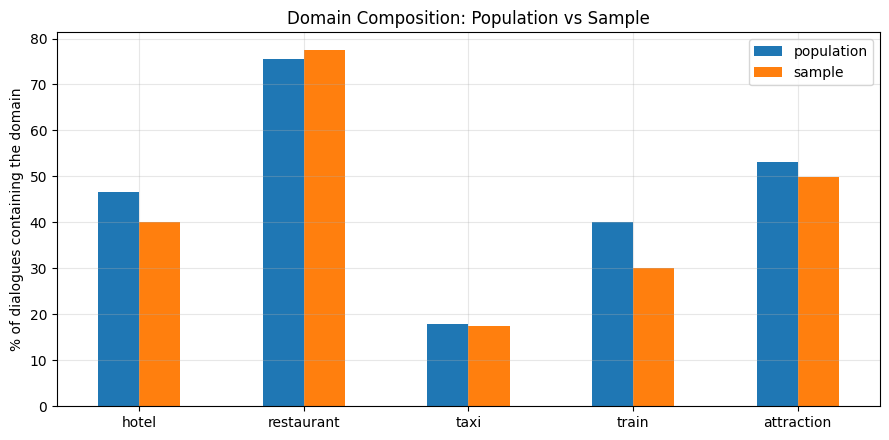

Multi-domain dialogues -> Population: 76.3%   Sample: 69.2%

INSIGHTS:
- Small differences (|<3 pp|) indicate that the domain composition is preserved; the sample is suitable for training a cross-domain model.
- Large differences in a specific domain suggest that the domain is over- or under-represented; consider re-weighting during training.



In [17]:
def domain_share(df):
    c = Counter()
    for doms in df["domains"]:
        for d in doms:
            c[d] += 1

    total = len(df)
    return {d: c.get(d, 0) / total for d in DOMAIN_KEYWORDS}


share_pop = domain_share(f_pop)
share_smp = domain_share(f_sample)

comp = pd.DataFrame({
    "population": share_pop,
    "sample": share_smp
})

comp["difference (pp)"] = (
    (comp["sample"] - comp["population"]) * 100
).round(1)

display(
    (comp[["population", "sample"]] * 100)
    .round(1)
    .rename(columns=lambda c: c + " (%)")
    .join(comp[["difference (pp)"]])
)

ax = comp[["population", "sample"]].mul(100).plot(kind="bar")

ax.set_ylabel("% of dialogues containing the domain")
ax.set_title("Domain Composition: Population vs Sample")

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("domain_composition.png", dpi=300, bbox_inches="tight")
plt.show()

# Multi-domain rate
md_pop = f_pop["is_multidomain"].mean() * 100
md_smp = f_sample["is_multidomain"].mean() * 100

print(
    f"Multi-domain dialogues -> Population: {md_pop:.1f}%   Sample: {md_smp:.1f}%"
)

print("""
INSIGHTS:
- Small differences (|<3 pp|) indicate that the domain composition is preserved; the sample is suitable for training a cross-domain model.
- Large differences in a specific domain suggest that the domain is over- or under-represented; consider re-weighting during training.
""")

## 4. Insight — Struktur Percakapan

Karakteristik turn yang penting untuk perancangan model (mis. `max_length`) dan untuk memahami
beban kerja agent.

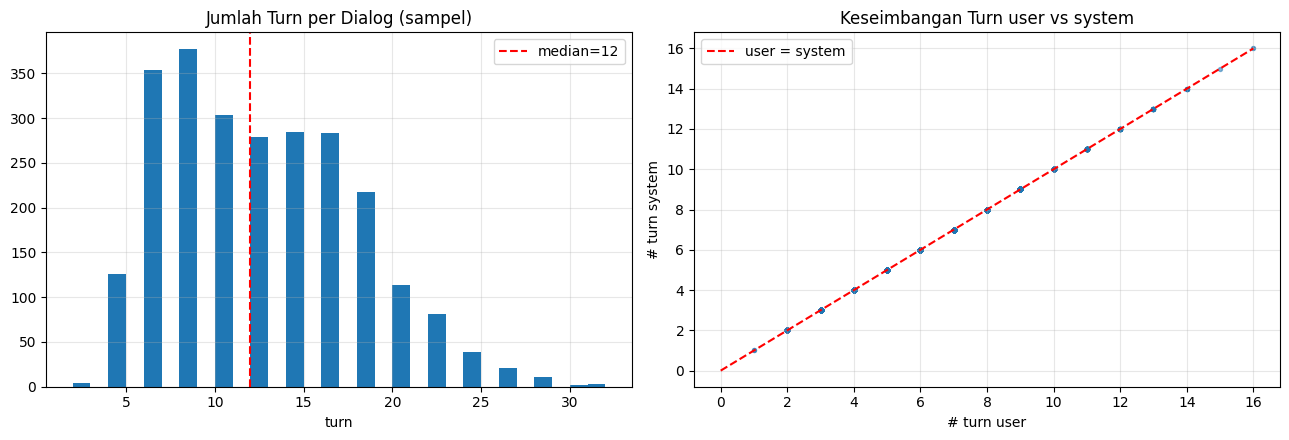

Median turn/dialog        : 12
Rasio user:system (median): 1.00
Panjang kata p95          : 327  -> usulan max_input_length >= 448 token

INSIGHT:
- Rasio user:system ~1.0 => percakapan bergantian rapi (tiap pertanyaan user dijawab system).
- p95 kata dipakai sebagai dasar max_length: nilai p95 x ~1.3 (faktor subword) dibulatkan ke kelipatan 64.
- Ekor kanan turn yang panjang = dialog multi-domain kompleks; ini kasus tersulit untuk model.



In [7]:
# rasio user vs system & balance turn
f_sample["user_sys_ratio"] = f_sample["n_user"] / f_sample["n_system"].replace(0,np.nan)

fig, axes = plt.subplots(1,2, figsize=(13,4.5))
axes[0].hist(f_sample["n_turns"], bins=30)
axes[0].axvline(f_sample["n_turns"].median(), color="r", ls="--",
                label=f'median={f_sample["n_turns"].median():.0f}')
axes[0].set_title("Jumlah Turn per Dialog (sampel)"); axes[0].set_xlabel("turn"); axes[0].legend()

axes[1].scatter(f_sample["n_user"], f_sample["n_system"], s=8, alpha=.3)
lim = max(f_sample["n_user"].max(), f_sample["n_system"].max())
axes[1].plot([0,lim],[0,lim],"r--",label="user = system")
axes[1].set_xlabel("# turn user"); axes[1].set_ylabel("# turn system")
axes[1].set_title("Keseimbangan Turn user vs system"); axes[1].legend()
plt.savefig("domain_composition.png", dpi=300, bbox_inches="tight")

plt.tight_layout(); plt.show()

p95_words = int(np.percentile(f_sample["n_words"],95))
print(f"Median turn/dialog        : {f_sample['n_turns'].median():.0f}")
print(f"Rasio user:system (median): {f_sample['user_sys_ratio'].median():.2f}")
print(f"Panjang kata p95          : {p95_words}  -> usulan max_input_length >= {int(np.ceil(p95_words*1.3/64)*64)} token")
print("""
INSIGHT:
- Rasio user:system ~1.0 => percakapan bergantian rapi (tiap pertanyaan user dijawab system).
- p95 kata dipakai sebagai dasar max_length: nilai p95 x ~1.3 (faktor subword) dibulatkan ke kelipatan 64.
- Ekor kanan turn yang panjang = dialog multi-domain kompleks; ini kasus tersulit untuk model.
""")

## 5. Insight — Analisis Cluster Sampling

`cluster_assignments` menunjukkan dari cluster mana tiap dialog terpilih. Di sini kita cek:
apakah pengambilan **seimbang antar-cluster**, dan apakah cluster benar-benar memisahkan
karakter dialog (mis. panjang berbeda antar cluster).

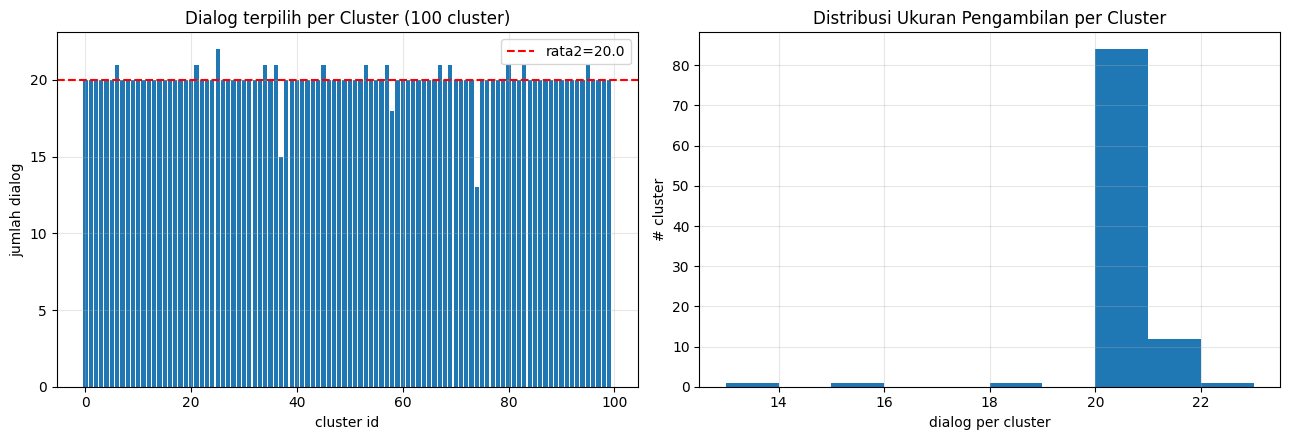

Jumlah cluster        : 100
Dialog/cluster        : min=13, max=22, mean=20.0
Koefisien variasi (CV): 0.049

INSIGHT:
- CV rendah (<0.15) => pengambilan hampir seragam antar-cluster (stratified sampling berjalan baik).
- Kalau ada cluster jauh lebih kecil => stratum itu kurang terwakili; periksa apakah cluster tsb
  memang langka di populasi atau ada masalah pengambilan.



In [18]:
clusters = list(cluster_map.values())
cc = Counter(clusters)
sizes = pd.Series(cc).sort_index()

fig, axes = plt.subplots(1,2, figsize=(13,4.5))
axes[0].bar(sizes.index, sizes.values)
axes[0].axhline(sizes.mean(), color="r", ls="--", label=f"rata2={sizes.mean():.1f}")
axes[0].set_title(f"Dialog terpilih per Cluster ({len(sizes)} cluster)")
axes[0].set_xlabel("cluster id"); axes[0].set_ylabel("jumlah dialog"); axes[0].legend()

axes[1].hist(sizes.values, bins=range(int(sizes.min()), int(sizes.max())+2))
axes[1].set_title("Distribusi Ukuran Pengambilan per Cluster")
axes[1].set_xlabel("dialog per cluster"); axes[1].set_ylabel("# cluster")
plt.savefig("jumlah_sample_per_dialogue.png", dpi=300, bbox_inches="tight")
plt.tight_layout(); plt.show()

cv = sizes.std()/sizes.mean()
print(f"Jumlah cluster        : {len(sizes)}")
print(f"Dialog/cluster        : min={sizes.min()}, max={sizes.max()}, mean={sizes.mean():.1f}")
print(f"Koefisien variasi (CV): {cv:.3f}")
print(f"""
INSIGHT:
- CV rendah (<0.15) => pengambilan hampir seragam antar-cluster (stratified sampling berjalan baik).
- Kalau ada cluster jauh lebih kecil => stratum itu kurang terwakili; periksa apakah cluster tsb
  memang langka di populasi atau ada masalah pengambilan.
""")

## 6. Insight — Profil Leksikal & Kosakata

Kata tersering (setelah buang stopword sederhana) memperlihatkan tema dominan dan jargon domain,
serta membantu validasi: vocabulary sampel harus mirip populasi.

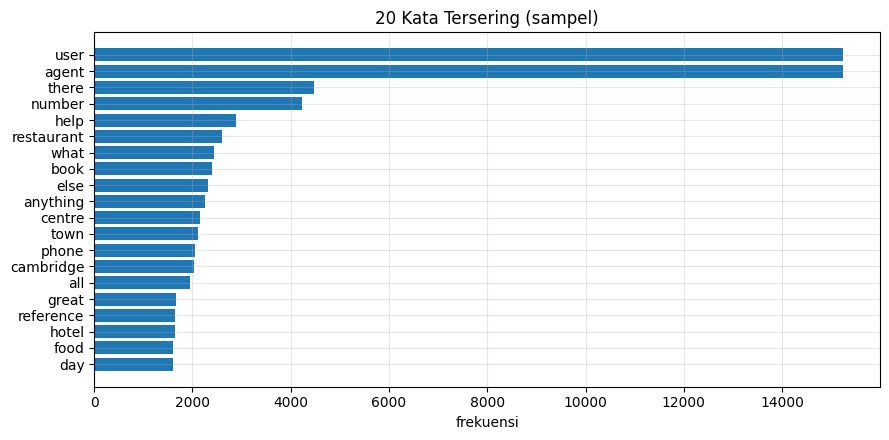

Overlap top-200 kata (sampel vs populasi): 96%

INSIGHT:
- Overlap tinggi (>85%) => kosakata inti sampel sepadan dengan populasi (representatif secara leksikal).
- Kata dominan biasanya menandai aksi pemesanan & atribut (book, restaurant, hotel, area, price) -
  ini sinyal intent utama yang harus ditangani model.



In [9]:
STOP = set('''a an the is am are was were be been being to of in on at for with and or but if then
this that these those i you he she it we they me him her them my your his its our their as by from
do does did have has had will would can could should may might must not no yes so just about
get got like need want looking would like hi hello thanks thank please could can you i'm i am'''.split())

def top_words(series, k=25):
    c = Counter()
    for txt in series:
        for w in re.findall(r"[a-z]+", str(txt).lower()):
            if w not in STOP and len(w) > 2:
                c[w]+=1
    return c

tw_sample = top_words(f_sample["text"])
tw_pop    = top_words(f_pop["text"])
top = tw_sample.most_common(20)
words = [w for w,_ in top]; vals=[v for _,v in top]
plt.barh(words[::-1], vals[::-1]); plt.title("20 Kata Tersering (sampel)")
plt.xlabel("frekuensi"); plt.tight_layout(); plt.show()

# overlap vocab populasi vs sampel (top 200)
top_pop = set([w for w,_ in tw_pop.most_common(200)])
top_smp = set([w for w,_ in tw_sample.most_common(200)])
overlap = len(top_pop & top_smp)/len(top_pop)*100
print(f"Overlap top-200 kata (sampel vs populasi): {overlap:.0f}%")
print("""
INSIGHT:
- Overlap tinggi (>85%) => kosakata inti sampel sepadan dengan populasi (representatif secara leksikal).
- Kata dominan biasanya menandai aksi pemesanan & atribut (book, restaurant, hotel, area, price) -
  ini sinyal intent utama yang harus ditangani model.
""")

## 7. Insight — Kualitas Data (penting sebelum training)

Cek duplikat, dialog terlalu pendek, kemungkinan PII, dan kebocoran antar-split.

In [10]:
# duplikat
dup_train = train.duplicated().sum()
dup_test  = test.duplicated().sum()
# overlap train-test (data leakage)
leak = len(set(train) & set(test))
# dialog sangat pendek (<2 turn)
short = (f_sample["n_turns"] < 2).sum()

# deteksi PII sederhana
PII = {
    "email":  re.compile(r"[\w.]+@[\w.]+"),
    "phone":  re.compile(r"\b\d{5,}\b"),
    "postcode_uk": re.compile(r"\b[a-z]{1,2}\d{1,2}[a-z]?\s*\d[a-z]{2}\b", re.I),
}
pii_counts = {k: f_sample["text"].str.contains(rx).sum() for k,rx in PII.items()}

print("== Kualitas Data ==")
print(f"Duplikat di train         : {dup_train}")
print(f"Duplikat di test          : {dup_test}")
print(f"Overlap train∩test (leak) : {leak}   <- idealnya 0")
print(f"Dialog < 2 turn           : {short}")
print(f"Potensi PII               : {pii_counts}")
print("""
INSIGHT / TINDAKAN:
- Overlap train-test harus 0; kalau >0 -> buang dari salah satu split agar evaluasi tidak bocor.
- PII (telepon/postcode/email) sebaiknya di-mask sebelum training utk privasi.
- Dialog <2 turn kemungkinan terpotong; pertimbangkan dibuang atau diperiksa manual.
""")

== Kualitas Data ==
Duplikat di train         : 0
Duplikat di test          : 0
Overlap train∩test (leak) : 0   <- idealnya 0
Dialog < 2 turn           : 0
Potensi PII               : {'email': 0, 'phone': 1360, 'postcode_uk': 839}

INSIGHT / TINDAKAN:
- Overlap train-test harus 0; kalau >0 -> buang dari salah satu split agar evaluasi tidak bocor.
- PII (telepon/postcode/email) sebaiknya di-mask sebelum training utk privasi.
- Dialog <2 turn kemungkinan terpotong; pertimbangkan dibuang atau diperiksa manual.



## 8. Ringkasan Eksekutif

Sel ini merangkum semua temuan menjadi satu laporan ringkas yang bisa langsung ditempel ke dokumentasi.

In [11]:
ks_turns = ks_2samp(f_pop["n_turns"], f_sample["n_turns"])
ks_words = ks_2samp(f_pop["n_words"], f_sample["n_words"])
max_dom_gap = comp["selisih (pp)"].abs().max()

print("="*64)
print(" RINGKASAN EDA SAMPLING ".center(64,"="))
print("="*64)
print(f"""
DATA
  Populasi        : {len(pop):,} dialog
  Sampel          : {len(f_sample):,} dialog (train {len(train):,} + test {len(test):,})
  Metode sampling : cluster-based / stratified, {len(set(clusters))} cluster

REPRESENTATIVITAS
  Panjang turn    : KS p={ks_turns.pvalue:.3g} -> {'representatif' if ks_turns.pvalue>0.05 else 'ADA PERGESERAN'}
  Panjang kata    : KS p={ks_words.pvalue:.3g} -> {'representatif' if ks_words.pvalue>0.05 else 'ADA PERGESERAN'}
  Komposisi domain: selisih maks {max_dom_gap:.1f} pp -> {'terjaga' if max_dom_gap<3 else 'perlu perhatian'}
  Overlap kosakata: {overlap:.0f}% (top-200)

STRUKTUR
  Median turn/dialog        : {f_sample['n_turns'].median():.0f}
  Rasio user:system (median): {f_sample['user_sys_ratio'].median():.2f}
  Usulan max_input_length   : {int(np.ceil(np.percentile(f_sample['n_words'],95)*1.3/64)*64)} token (p95 x 1.3)

KUALITAS
  Duplikat (train/test)     : {dup_train} / {dup_test}
  Kebocoran train-test      : {leak}
  Potensi PII               : {pii_counts}
""")
print("="*64)

==================== RINGKASAN EDA SAMPLING ====================

DATA
  Populasi        : 8,437 dialog
  Sampel          : 2,499 dialog (train 2,000 + test 499)
  Metode sampling : cluster-based / stratified, 100 cluster

REPRESENTATIVITAS
  Panjang turn    : KS p=2.51e-24 -> ADA PERGESERAN
  Panjang kata    : KS p=8.27e-27 -> ADA PERGESERAN
  Komposisi domain: selisih maks 10.0 pp -> perlu perhatian
  Overlap kosakata: 96% (top-200)

STRUKTUR
  Median turn/dialog        : 12
  Rasio user:system (median): 1.00
  Usulan max_input_length   : 448 token (p95 x 1.3)

KUALITAS
  Duplikat (train/test)     : 0 / 0
  Kebocoran train-test      : 0
  Potensi PII               : {'email': 0, 'phone': 1360, 'postcode_uk': 839}



## 9. Keterkaitan & Ketersebaran Antar-Cluster (ruang embedding SBERT)

> **Penting:** cluster di `audit.json` dibuat dari **embedding semantik (SBERT)**, bukan dari kata.
> Karena itu validasi harus dilakukan di **ruang embedding yang sama**, bukan TF-IDF — kalau tidak,
> hasilnya menyesatkan (cluster terlihat "tumpang-tindih" padahal hanya beda ruang ukur).

Tujuan: ukur apakah cluster **kohesif di dalam** dan **terpisah antar** cluster, di ruang yang benar.

**Sediakan embedding Anda lewat salah satu cara:**
- **Mode A (disarankan):** simpan embedding yang dipakai saat clustering ke file `.npy`
  (urutannya sejajar dengan `selected_ids`) lalu set `EMB_PATH`.
- **Mode B:** biarkan sel meng-encode ulang teks dengan model SBERT yang sama (`MODEL_NAME`).
  Pastikan nama model **identik** dengan yang dipakai saat membuat cluster.

Mode B: encode ulang dgn 'all-MiniLM-L6-v2' ... (pastikan model sama dgn saat clustering)


Batches: 100%|██████████| 32/32 [00:01<00:00, 22.51it/s]


Dialog dianalisis: 2000 | cluster unik: 100 | dim embedding: 384

Silhouette score (cosine, ruang embedding): 0.046


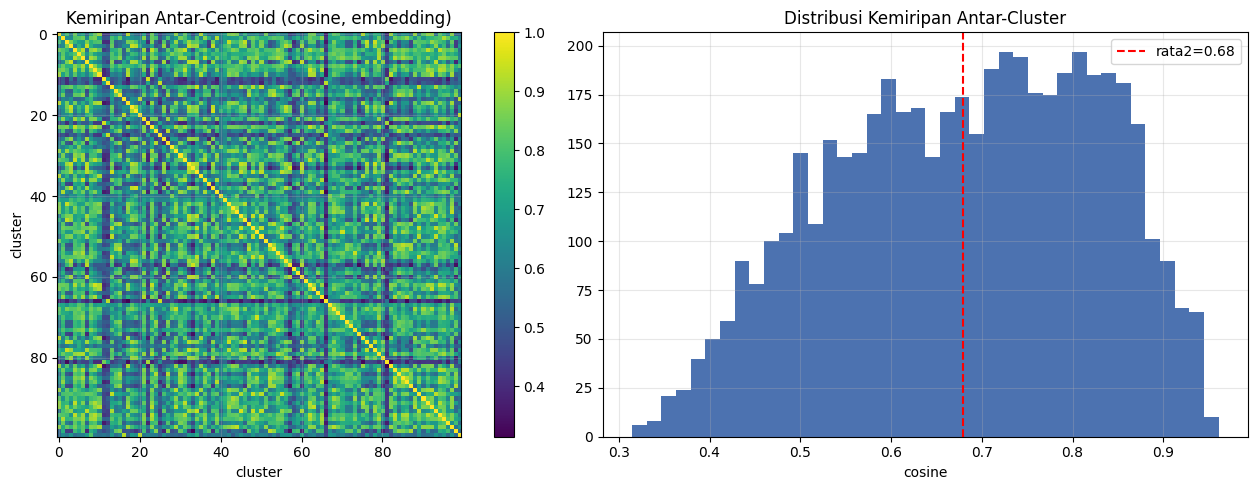

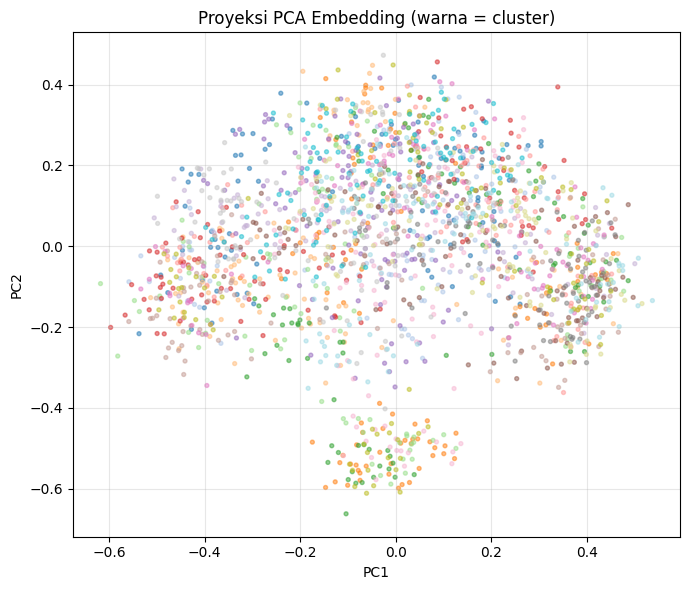


Intra-cluster similarity : 0.696
Inter-cluster similarity : 0.680
Rasio intra/inter        : 1.02   (makin >1 makin terpisah)
Pasangan cluster sim>0.7 : 2375 dari 4950

INSIGHT:
- Silhouette > 0.25 & rasio intra/inter > 1.3 => cluster SBERT terpisah baik; stratifikasi bermakna,
  dan sampel mewakili tiap kelompok semantik secara proporsional.
- Silhouette ~0 / rasio ~1 => cluster tumpang-tindih BAHKAN di ruang embedding; clustering perlu ditinjau
  (jumlah k, normalisasi, atau kualitas embedding).
- Bandingkan dgn hasil TF-IDF sebelumnya: jika di embedding terpisah tapi di TF-IDF tidak, itu WAJAR —
  cluster memisahkan makna, bukan pilihan kata.


In [12]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

# ============ KONFIG: pilih sumber embedding ============
EMB_PATH   = None                         # Mode A: path ke .npy (sejajar selected_ids). Contoh: "embeddings.npy"
MODEL_NAME = "all-MiniLM-L6-v2"           # Mode B: nama model SBERT yang SAMA dgn saat clustering
# ========================================================

# --- label cluster sejajar dgn selected_ids & teks train ---
ids_order  = [str(i) for i in selected_ids]
labels_all = np.array([cluster_map.get(i, -1) for i in ids_order])
texts_all  = train.reset_index(drop=True)
n = min(len(texts_all), len(labels_all))
texts, labels = texts_all.iloc[:n].tolist(), labels_all[:n]
mask = labels != -1
texts  = [t for t, m in zip(texts, mask) if m]
labels = labels[mask]

# --- ambil embedding ---
emb = None
if EMB_PATH:
    emb = np.load(EMB_PATH)
    emb = emb[:n][mask]
    print(f"Mode A: embedding dimuat dari {EMB_PATH} -> shape {emb.shape}")
else:
    try:
        from sentence_transformers import SentenceTransformer
        print(f"Mode B: encode ulang dgn '{MODEL_NAME}' ... (pastikan model sama dgn saat clustering)")
        emb = SentenceTransformer(MODEL_NAME).encode(texts, show_progress_bar=True,
                                                      batch_size=64, normalize_embeddings=True)
    except Exception as e:
        print("!! sentence-transformers tidak tersedia / model gagal dimuat:", repr(e))
        print("   -> Set EMB_PATH ke file .npy embedding Anda (Mode A), lalu jalankan ulang sel ini.")

assert emb is not None, "Embedding belum tersedia. Isi EMB_PATH (Mode A) atau install model (Mode B)."
print(f"Dialog dianalisis: {len(labels)} | cluster unik: {len(set(labels))} | dim embedding: {emb.shape[1]}")

# --- 1. Silhouette di ruang embedding (cosine) ---
sil = silhouette_score(emb, labels, metric="cosine",
                       sample_size=min(2000, len(labels)), random_state=0)
print(f"\nSilhouette score (cosine, ruang embedding): {sil:.3f}")

# --- 2. Centroid per cluster + matriks kemiripan ---
uniq = sorted(set(labels))
cent = np.vstack([emb[labels == c].mean(axis=0) for c in uniq])
sim  = cosine_similarity(cent)
off  = sim[np.triu_indices_from(sim, k=1)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im = axes[0].imshow(sim, cmap="viridis"); axes[0].set_title("Kemiripan Antar-Centroid (cosine, embedding)")
axes[0].set_xlabel("cluster"); axes[0].set_ylabel("cluster"); plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].hist(off, bins=40, color="#4C72B0")
axes[1].axvline(off.mean(), color="r", ls="--", label=f"rata2={off.mean():.2f}")
axes[1].set_title("Distribusi Kemiripan Antar-Cluster"); axes[1].set_xlabel("cosine"); axes[1].legend()
plt.tight_layout(); plt.show()

# --- 3. PCA 2D ---
coords = PCA(n_components=2, random_state=0).fit_transform(emb)
plt.figure(figsize=(7, 6))
plt.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab20", s=8, alpha=.5)
plt.title("Proyeksi PCA Embedding (warna = cluster)"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()

# --- 4. Intra vs inter ---
intra = []
for c in uniq:
    sub = emb[labels == c]
    if len(sub) > 1:
        s = cosine_similarity(sub); intra.append(s[np.triu_indices_from(s, k=1)].mean())
intra_mean, inter_mean = np.mean(intra), off.mean()
print(f"""
Intra-cluster similarity : {intra_mean:.3f}
Inter-cluster similarity : {inter_mean:.3f}
Rasio intra/inter        : {intra_mean/inter_mean:.2f}   (makin >1 makin terpisah)
Pasangan cluster sim>0.7 : {(off>0.7).sum()} dari {len(off)}
""")
print("""INSIGHT:
- Silhouette > 0.25 & rasio intra/inter > 1.3 => cluster SBERT terpisah baik; stratifikasi bermakna,
  dan sampel mewakili tiap kelompok semantik secara proporsional.
- Silhouette ~0 / rasio ~1 => cluster tumpang-tindih BAHKAN di ruang embedding; clustering perlu ditinjau
  (jumlah k, normalisasi, atau kualitas embedding).
- Bandingkan dgn hasil TF-IDF sebelumnya: jika di embedding terpisah tapi di TF-IDF tidak, itu WAJAR —
  cluster memisahkan makna, bukan pilihan kata.""")